# Quantitative Finance Algorithms
Arthur Cooper 09/25
***

In [1]:
# Python Libraries
import numpy as np
import pandas as pd
from scipy import stats, optimize, signal
import matplotlib.pyplot as plt
from math import exp as e
import yfinance as yf

## Stock Market Basics

### Present and Future Value

In [3]:
# discrete future value function
def future_discrete_value(x, r, n):
    return x*(1+r)**n

# discrete present value function
def present_discrete_value(x, r, n):
    return x*(1+r)**-n

# continuous future value function
def future_continuous_value(x, r, n):
    return x*e(r*n)

# continuous present value function
def present_continuous_value(x, r, n):
    return x*e(-r*n)

# where x is the nominal cash value, r is the interest rate, n is the number of time periods where the interest rate is applied

if __name__ == '__main__':

    # value of investment in dollars
    x = 100
    # define the investment rate (r)
    r = 0.05
    # duration (years)
    n = 5 

    print("Future value (discrete model) of x: %s" % future_discrete_value(x, r, n))
    print("Present value (discrete model) of x: %s" % present_discrete_value(x, r, n))
    print("Future value (continuous model) of x: %s" % future_continuous_value(x, r, n))
    print("Present value (continuous model) of x: %s" % present_continuous_value(x, r, n))

''' In Python, every file has a __name__.

When you run the file directly, __name__ is '__main__', so the code under that if executes.

When you import the file as a module, __name__ is the module’s name, so the block doesn’t run.
This pattern lets you keep reusable functions at the top of the file and only run demo/tests when executed directly. '''

print("This shows the time value of money --> money today is worth more than money in the future")

Future value (discrete model) of x: 127.62815625000003
Present value (discrete model) of x: 78.35261664684589
Future value (continuous model) of x: 128.40254166877415
Present value (continuous model) of x: 77.8800783071405
This shows the time value of money --> money today is worth more than money in the future


## Bond Theory

In [6]:
# zero coupon bond class
class ZeroCouponBonds:
    def __init__(self, principal, maturity, interest_rate):
        # principal amount
        self.principal = principal
        # date to maturity
        self.maturity = maturity
        # market interest rate (discounting rate)
        self.interest_rate = interest_rate/100

    def present_value(self, x, n):
        return x / (1+self.interest_rate)**n

    def calculate_price(self):
        return self.present_value(self.principal, self.maturity)

if __name__ == '__main__':
    bond = ZeroCouponBonds(1000, 2, 4)
    print("Price of a zero coupon bond in $: %.2f" % bond.calculate_price())

Price of a zero coupon bond in $: 924.56


In [8]:
# coupon bond class
class CouponBond:

    def __init__(self, principal, rate, maturity, interest_rate):
        # principal amount
        self.principal = principal
        # coupon rate
        self.rate = rate/100
        # date to maturity
        self.maturity = maturity
        # market interest rate (discounting rate)
        self.interest_rate = interest_rate/100

    def present_value(self, x, n):
        return x / (1+self.interest_rate)**n

    def calculate_price(self):
        price = 0
        # discount the coupon payments
        for t in range(1, self.maturity+1):
            price = price + self.present_value(self.principal*self.rate, t)
        #discount the principal
        price = price + self.present_value(self.principal, self.maturity)

        return price

if __name__=='__main__':
    bond = CouponBond(1000,10,3,4)
    print("Price of coupon bond in $: %s" % round(bond.calculate_price(),2))

Price of coupon bond in $: 1166.51


In [12]:
# zero coupon bond class (continous model)
class ZeroCouponBonds:
    def __init__(self, principal, maturity, interest_rate):
        # principal amount
        self.principal = principal
        # date to maturity
        self.maturity = maturity
        # market interest rate (discounting rate)
        self.interest_rate = interest_rate/100

    def present_value(self, x, n):
        return x * e(-self.interest_rate*n)

    def calculate_price(self):
        return self.present_value(self.principal, self.maturity)

if __name__ == '__main__':
    bond = ZeroCouponBonds(1000, 2, 4)
    print("Price of a zero coupon bond in $ (continous model): %.2f" % bond.calculate_price())

Price of a zero coupon bond in $ (continous model): 923.12


## Modern Portfolio Theory - The Markowitz Model

In [15]:
from datetime import date

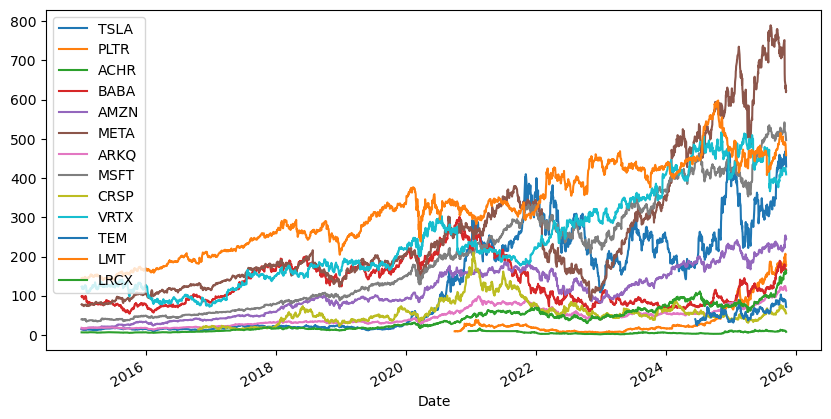

In [17]:
# Stocks we are going to put in our portfolio
stocks = ['TSLA', 'PLTR', 'ACHR', 'BABA', 'AMZN', 'META', 'ARKQ', 'MSFT', 'CRSP','VRTX', 'TEM', 'LMT', 'LRCX']

# Historical data
start_date = '2015-01-01'
end_date = str(date.today())

#Download the data

def download_data():
    #name of the stock ticker
    stock_data = {}

    for stock in stocks:
        ticker = yf.Ticker(stock)
        stock_data[stock] = ticker.history(start=start_date, end=end_date)['Close']
    
    return pd.DataFrame(stock_data)

def show_data(data):
    data.plot(figsize=(10,5))
    plt.show()


if __name__ == '__main__':
    dataset = download_data()
    show_data(dataset)

Pandas library does not consider NaNs by default, therefore it is valid to use .mean() and .cov() as it won't consider NaNs in the mean and for pairwise covariances.

In [19]:
def calculate_return(data):
    # NORMALISATION - to measure all the variables in comparable metrics
    log_return = np.log(data/data.shift(1))
    return log_return[1:] # returns rows from 1 to n, removes first row as they are all NaN

NUM_TRADING_DAYS = 252

def show_statistics(returns):
    # instead of daily metrics we are after annual metrics
    # mean of annual returns 
    print(returns.mean() * NUM_TRADING_DAYS)
    print(returns.cov() * NUM_TRADING_DAYS)

if __name__ == '__main__':
    dataset = download_data()
    log_daily_returns = calculate_return(dataset)
    show_statistics(log_daily_returns)

TSLA    0.312136
PLTR    0.575514
ACHR   -0.040642
BABA    0.048490
AMZN    0.255120
META    0.191716
ARKQ    0.168219
MSFT    0.232795
CRSP    0.151028
VRTX    0.111005
TEM     0.413127
LMT     0.106448
LRCX    0.291061
dtype: float64
          TSLA      PLTR      ACHR      BABA      AMZN      META      ARKQ  \
TSLA  0.333719  0.195573  0.170644  0.069712  0.077078  0.074610  0.110971   
PLTR  0.195573  0.489193  0.204502  0.092117  0.106373  0.111000  0.138598   
ACHR  0.170644  0.204502  0.677501  0.101768  0.090577  0.096713  0.152258   
BABA  0.069712  0.092117  0.101768  0.175798  0.048262  0.055316  0.057792   
AMZN  0.077078  0.106373  0.090577  0.048262  0.108267  0.074763  0.055026   
META  0.074610  0.111000  0.096713  0.055316  0.074763  0.144347  0.057379   
ARKQ  0.110971  0.138598  0.152258  0.057792  0.055026  0.057379  0.081109   
MSFT  0.064209  0.070725  0.056129  0.038708  0.057993  0.060179  0.047586   
CRSP  0.112033  0.172933  0.150555  0.081099  0.077829  0.0784

TSLA    0.312136
PLTR    0.575514
ACHR   -0.040642
BABA    0.048490
AMZN    0.255120
META    0.191716
ARKQ    0.168219
MSFT    0.232795
CRSP    0.151028
VRTX    0.111005
TEM     0.413127
LMT     0.106448
LRCX    0.291061
dtype: float64
          TSLA      PLTR      ACHR      BABA      AMZN      META      ARKQ  \
TSLA  0.333719  0.195573  0.170644  0.069712  0.077078  0.074610  0.110971   
PLTR  0.195573  0.489193  0.204502  0.092117  0.106373  0.111000  0.138598   
ACHR  0.170644  0.204502  0.677501  0.101768  0.090577  0.096713  0.152258   
BABA  0.069712  0.092117  0.101768  0.175798  0.048262  0.055316  0.057792   
AMZN  0.077078  0.106373  0.090577  0.048262  0.108267  0.074763  0.055026   
META  0.074610  0.111000  0.096713  0.055316  0.074763  0.144347  0.057379   
ARKQ  0.110971  0.138598  0.152258  0.057792  0.055026  0.057379  0.081109   
MSFT  0.064209  0.070725  0.056129  0.038708  0.057993  0.060179  0.047586   
CRSP  0.112033  0.172933  0.150555  0.081099  0.077829  0.0784

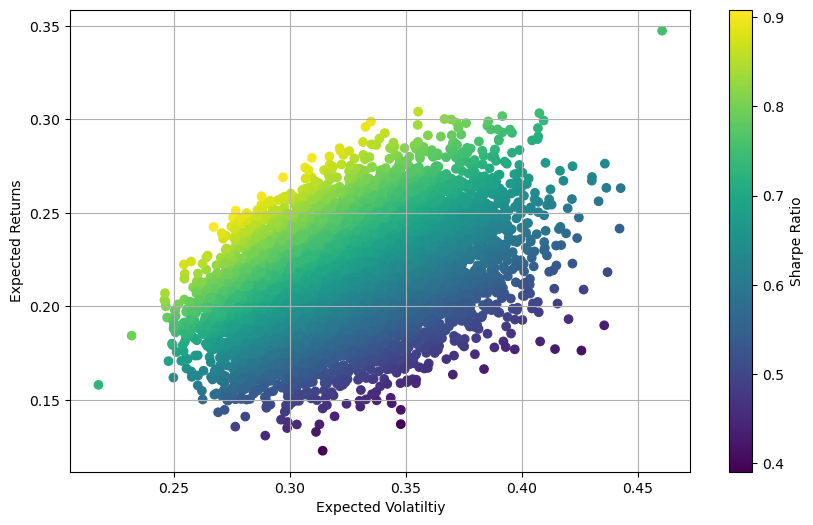

In [21]:
# Generating portfolios with random weights

def show_mean_variance(returns, weights):
    portfolio_return = np.sum(returns.mean()*weights) * NUM_TRADING_DAYS
    portfoilo_volatility = np.sqrt(np.dot(weights.T, np.dot(returns.cov()*NUM_TRADING_DAYS,weigths)))

    print("Expected portfolio mean (return): ", portfolio_return)
    print("Expected portfolio volatility (std): ", portfoilo_volatility)

NUM_PORTFOLIOS = 10000

def generate_portfolios(returns):

    portfolio_means = []
    portfolio_risks = []
    portfolio_weights = []

    for _ in range(NUM_PORTFOLIOS):
        w = np.random.random(len(stocks))
        w /= np.sum(w)
        portfolio_weights.append(w)
        portfolio_means.append(np.sum(returns.mean()*w)*NUM_TRADING_DAYS)
        portfolio_risks.append(np.sqrt(np.dot(w.T, np.dot(returns.cov()*NUM_TRADING_DAYS,w))))

    return np.array(portfolio_weights), np.array(portfolio_means), np.array(portfolio_risks)


def show_portfolios(returns, volatilities):
    plt.figure(figsize=(10,6))
    plt.scatter(volatilities, returns, c=returns/volatilities, marker='o')
    plt.grid(True)
    plt.xlabel('Expected Volatiltiy')
    plt.ylabel('Expected Returns')
    plt.colorbar(label='Sharpe Ratio')
    plt.show()

if __name__ == '__main__':
    dataset = download_data()
    log_daily_returns = calculate_return(dataset)
    show_statistics(log_daily_returns)

    weights, means, risks = generate_portfolios(log_daily_returns)
    show_portfolios(means, risks)
    

TSLA    0.315089
PLTR    0.581404
ACHR    0.031203
BABA    0.060361
AMZN    0.247465
META    0.205937
ARKQ    0.172507
MSFT    0.238721
CRSP    0.175786
VRTX    0.110616
TEM     0.636166
LMT     0.116371
LRCX    0.285477
dtype: float64
          TSLA      PLTR      ACHR      BABA      AMZN      META      ARKQ  \
TSLA  0.334246  0.196465  0.167889  0.069104  0.076632  0.074232  0.110590   
PLTR  0.196465  0.493783  0.203710  0.092353  0.105749  0.111521  0.137926   
ACHR  0.167889  0.203710  0.672466  0.100303  0.090411  0.096004  0.149318   
BABA  0.069104  0.092353  0.100303  0.175327  0.048313  0.054879  0.057361   
AMZN  0.076632  0.105749  0.090411  0.048313  0.107623  0.074948  0.054597   
META  0.074232  0.111521  0.096004  0.054879  0.074948  0.143781  0.057164   
ARKQ  0.110590  0.137926  0.149318  0.057361  0.054597  0.057164  0.080394   
MSFT  0.064300  0.071197  0.055516  0.038672  0.058350  0.060161  0.047622   
CRSP  0.112017  0.173435  0.147284  0.081306  0.077748  0.0786

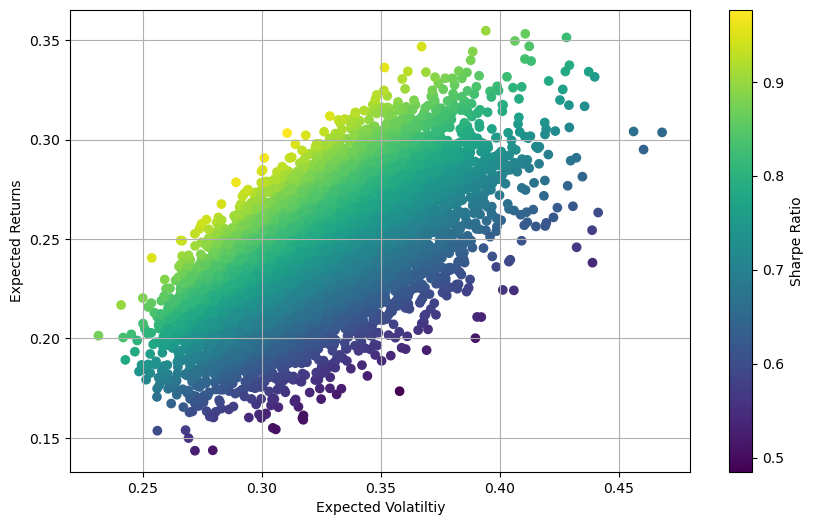

Optimal portfolio:  [0.    0.175 0.    0.    0.    0.    0.    0.414 0.    0.    0.07  0.341
 0.   ]
Expected return, volatility and sharpe ratio:  [0.28479041 0.25188129 1.13065328]


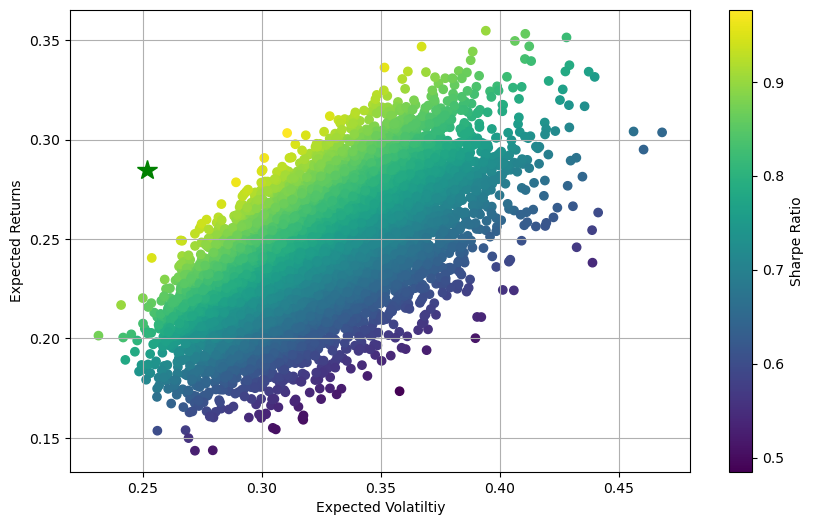

In [62]:
# Optimising the portfolio weights

def statistics(weights, returns):
    portfolio_return = np.sum(returns.mean() * weights) * NUM_TRADING_DAYS
    portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(returns.cov() * NUM_TRADING_DAYS, weights)))

    return np.array([portfolio_return, portfolio_volatility, portfolio_return / portfolio_volatility])

# scipy optimise module can find the minimum of a given function
# the maximum of a f(x) is the minimum of -f(x)
def min_function_sharpe(weights, returns):
    return -statistics(weights, returns)[2]

# what are the constraints? sum of the weights = 1
# sum w = f(x) = 0 this is the function to minimise
# therefore sum w - 1 = 0
def optimize_portfolio(weights, returns):
    constraints = {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}
    # the weights can be 1 at the most when investing 100% of money into a stock
    bound = tuple((0,1) for _ in range(len(stocks)))
    return optimize.minimize(fun= min_function_sharpe, x0=weights[0], args=returns, method='SLSQP', bounds=bound, constraints=constraints)


def print_optimal_portfolios(optimum, returns):
    print("Optimal portfolio: ", optimum['x'].round(3))
    print("Expected return, volatility and sharpe ratio: ", statistics(optimum['x'].round(3),returns))


def show_optimal_portfolio(optimum, rets, portfolio_rets, portfolio_vols):
    plt.figure(figsize=(10,6))
    plt.scatter(portfolio_vols, portfolio_rets, c=portfolio_rets/portfolio_vols, marker='o')
    plt.grid(True)
    plt.xlabel('Expected Volatiltiy')
    plt.ylabel('Expected Returns')
    plt.colorbar(label='Sharpe Ratio')
    plt.plot(statistics(optimum['x'], rets)[1], statistics(optimum['x'], rets)[0], 'g*', markersize= 15)
    plt.show()


if __name__ == '__main__':
    dataset = download_data()
    log_daily_returns = calculate_return(dataset)
    show_statistics(log_daily_returns)

    pweights, means, risks = generate_portfolios(log_daily_returns)
    show_portfolios(means, risks)
    optimum = optimize_portfolio(pweights, log_daily_returns)
    print_optimal_portfolios(optimum, log_daily_returns)
    show_optimal_portfolio(optimum, log_daily_returns, means, risks)

In [23]:
print(stocks)

['TSLA', 'PLTR', 'ACHR', 'BABA', 'AMZN', 'META', 'ARKQ', 'MSFT', 'CRSP', 'VRTX', 'TEM', 'LMT', 'LRCX']
